In [67]:
import sys
print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
Python executable: c:\Users\cerik\Documents\Uplift Milestone 3_Group 1\.venv\Scripts\python.exe


In [68]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [69]:
from pathlib import Path
import pandas as pd

# Load Ames Housing dataset
project = Path(r"C:\Users\cerik\Documents\Uplift Milestone 3_Group 1")

data_path = project / "Data" / "Regression" / "AmesHousing.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 2930
Columns: 82


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [70]:
# Check dataset information
print("Dataset dimensions:", df.shape)
print("Duplicate records:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())

# View column names
print("\nColumn names:")
print(df.columns.tolist())

# Summary of sale prices
display(df["SalePrice"].describe())

Dataset dimensions: (2930, 82)
Duplicate records: 0
Missing values: 15749

Column names:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [71]:
# Check missing values by column
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values:")
display(missing.to_frame("Missing Values"))

print("Total missing values:", df.isna().sum().sum())
print("Duplicate records:", df.duplicated().sum())

Columns with missing values:


,Missing Values
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Qual,159
Garage Cond,159
Garage Yr Blt,159


Total missing values: 15749
Duplicate records: 0


In [72]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove exact duplicates
df_clean = df_clean.drop_duplicates().copy()

# Validate sale prices
if df_clean["SalePrice"].isna().any():
    raise ValueError("Missing SalePrice values found.")

if (df_clean["SalePrice"] <= 0).any():
    raise ValueError("Invalid SalePrice values found.")

# Handle missing values for absent property features
no_feature_columns = [
    "Alley", "Mas Vnr Type", "Bsmt Qual", "Bsmt Cond",
    "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2",
    "Fireplace Qu", "Garage Type", "Garage Finish",
    "Garage Qual", "Garage Cond", "Pool QC",
    "Fence", "Misc Feature"
]

for column in no_feature_columns:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].fillna("NoFeature")

# Treat building classification as categorical
df_clean["MS SubClass"] = (
    df_clean["MS SubClass"]
    .astype("string")
    .fillna("Missing")
)

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining missing values:", df_clean.isna().sum().sum())

Original dataset: (2930, 82)
Cleaned dataset: (2930, 82)
Remaining missing values: 683


In [73]:
# Check unusual numerical values
columns = ["SalePrice", "Gr Liv Area", "Lot Area", "Total Bsmt SF"]

for column in columns:
    values = df_clean[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((values < lower) | (values > upper)).sum()

    print(f"{column}: {outliers} potential outliers")

# Check construction and sale years
year_issues = df_clean[
    df_clean["Year Built"] > df_clean["Yr Sold"]
]

print("Construction year inconsistencies:", len(year_issues))

SalePrice: 137 potential outliers
Gr Liv Area: 75 potential outliers
Lot Area: 127 potential outliers
Total Bsmt SF: 123 potential outliers
Construction year inconsistencies: 1


In [74]:
# Save cleaned dataset
cleaned_path = (
    project / "Data" / "Regression" /
    "Processed" / "AmesHousing_cleaned.csv"
)

cleaned_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(cleaned_path, index=False)

# Verify saved file
df_verified = pd.read_csv(
    cleaned_path,
    dtype={"MS SubClass": "string"}
)

assert df_verified.shape == df_clean.shape
assert (
    df_verified.isna().sum().sum()
    == df_clean.isna().sum().sum()
)

print("Cleaned dataset saved successfully.")
print("File location:", cleaned_path)
print("Dataset shape:", df_verified.shape)
print("Remaining missing values:", df_verified.isna().sum().sum())

Cleaned dataset saved successfully.
File location: C:\Users\cerik\Documents\Uplift Milestone 3_Group 1\Data\Regression\Processed\AmesHousing_cleaned.csv
Dataset shape: (2930, 82)
Remaining missing values: 683


In [75]:
# Set folder for visualizations
figures = project / "Reports" / "Figures" / "Regression"
figures.mkdir(parents=True, exist_ok=True)

print("Figures folder:", figures)

Figures folder: C:\Users\cerik\Documents\Uplift Milestone 3_Group 1\Reports\Figures\Regression


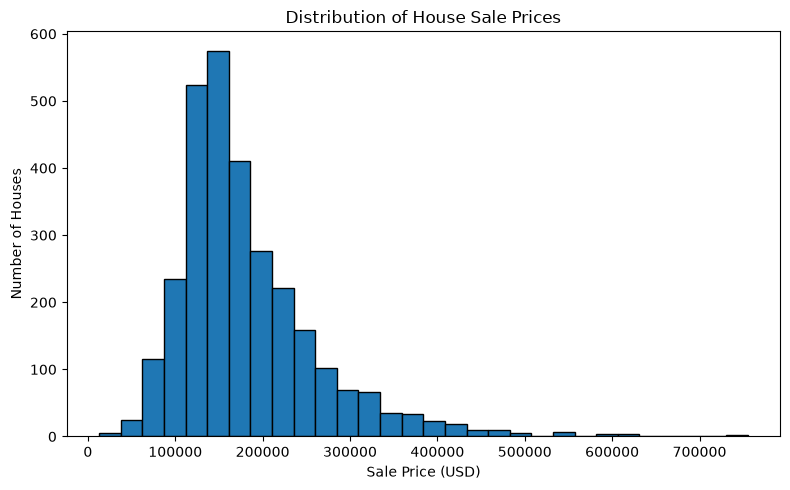

In [76]:
# Distribution of sale prices
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["SalePrice"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price (USD)")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.savefig(figures / "01_saleprice_distribution.png", dpi=150)
plt.show()

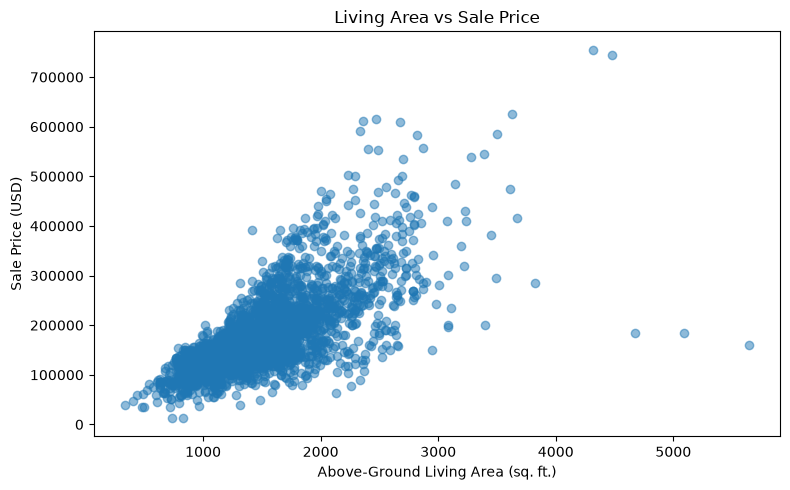

In [77]:
# Living area and sale price
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Gr Liv Area"],
    df_clean["SalePrice"],
    alpha=0.5
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area (sq. ft.)")
plt.ylabel("Sale Price (USD)")

plt.tight_layout()
plt.savefig(figures / "02_living_area_vs_saleprice.png", dpi=150)
plt.show()

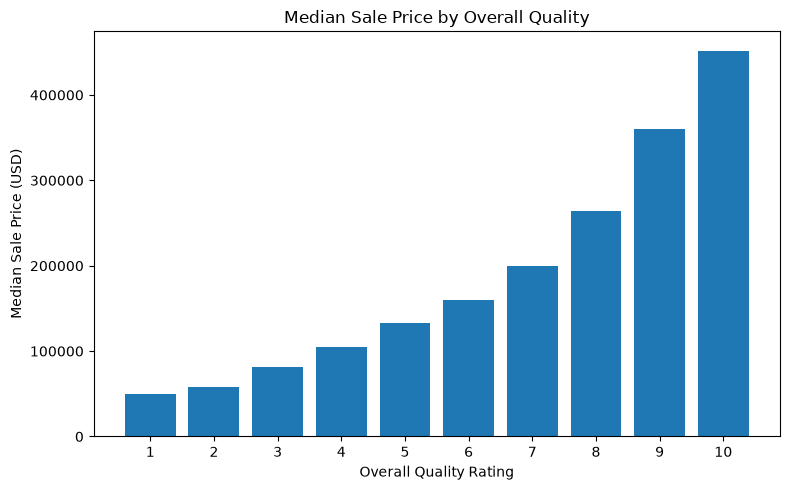

In [78]:
# Median sale price by overall quality
quality = df_clean.groupby("Overall Qual")["SalePrice"].median()

plt.figure(figsize=(8, 5))

plt.bar(
    quality.index.astype(str),
    quality.values
)

plt.title("Median Sale Price by Overall Quality")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Median Sale Price (USD)")

plt.tight_layout()
plt.savefig(figures / "03_quality_vs_saleprice.png", dpi=150)
plt.show()

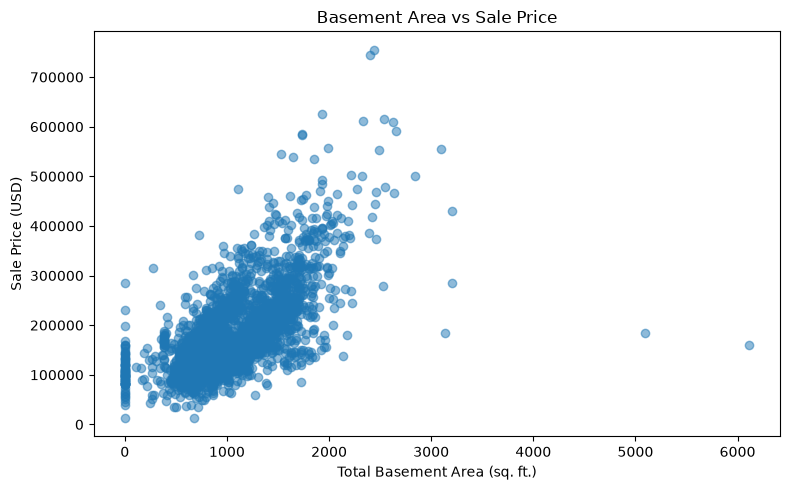

In [79]:
# Basement area and sale price
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Total Bsmt SF"],
    df_clean["SalePrice"],
    alpha=0.5
)

plt.title("Basement Area vs Sale Price")
plt.xlabel("Total Basement Area (sq. ft.)")
plt.ylabel("Sale Price (USD)")

plt.tight_layout()
plt.savefig(figures / "04_basement_vs_saleprice.png", dpi=150)
plt.show()

In [80]:
# Correlation with sale price
numeric_df = df_clean.select_dtypes(include=np.number)

numeric_df = numeric_df.drop(
    columns=["Order", "PID"],
    errors="ignore"
)

correlations = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .dropna()
)

print("Top positive correlations:")
display(
    correlations.sort_values(ascending=False)
    .head(10)
    .to_frame("Correlation")
)

print("Top negative correlations:")
display(
    correlations.sort_values()
    .head(10)
    .to_frame("Correlation")
)

Top positive correlations:


,Correlation
Overall Qual,0.799262
Gr Liv Area,0.706780
Garage Cars,0.647877
Garage Area,0.640401
Total Bsmt SF,0.632280
1st Flr SF,0.621676
Year Built,0.558426
Full Bath,0.545604
Year Remod/Add,0.532974
Garage Yr Blt,0.526965


Top negative correlations:


,Correlation
Enclosed Porch,-0.128787
Kitchen AbvGr,-0.119814
Overall Cond,-0.101697
Low Qual Fin SF,-0.037660
Bsmt Half Bath,-0.035835
Yr Sold,-0.030569
Misc Val,-0.015691
BsmtFin SF 2,0.005891
3Ssn Porch,0.032225
Mo Sold,0.035259


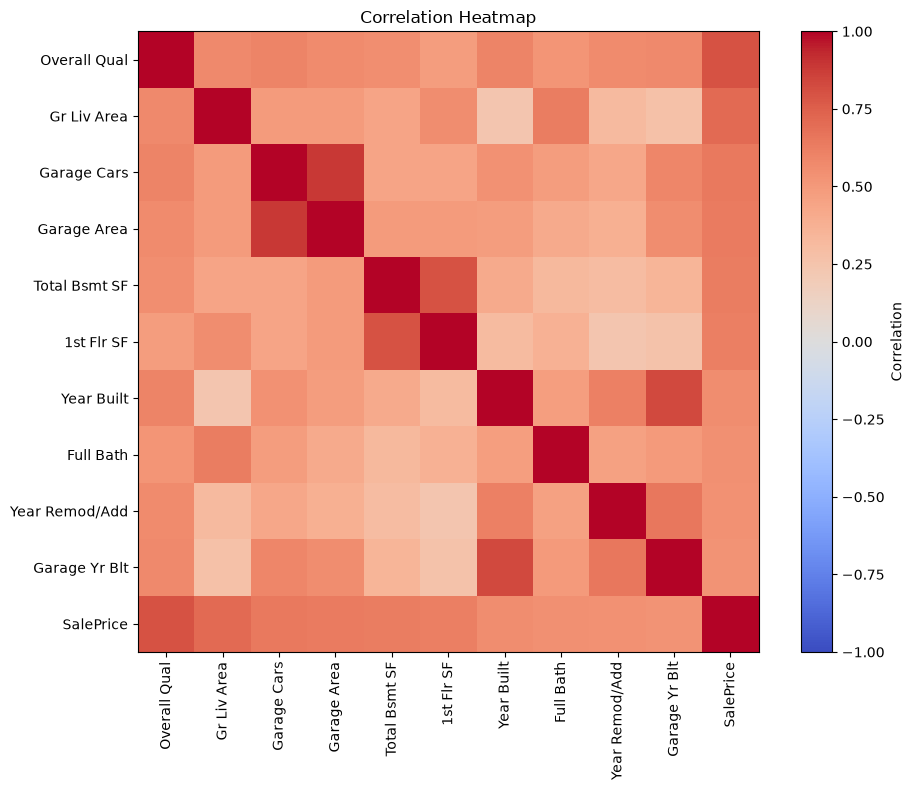

In [81]:
# Correlation heatmap
top_features = (
    correlations.abs()
    .sort_values(ascending=False)
    .head(10)
    .index.tolist()
)

corr_matrix = numeric_df[top_features + ["SalePrice"]].corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.savefig(figures / "05_correlation_heatmap.png", dpi=150)
plt.show()

## Regression Model Development

The regression models use property characteristics to estimate SalePrice. Record identifiers are excluded from the predictors.

In [100]:
# Separate features and target
X = df_clean.drop(columns=["SalePrice", "Order", "PID"])
y = df_clean["SalePrice"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (2930, 79)
Target: (2930,)


In [101]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2344
Testing records: 586


In [102]:
# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 35
Categorical features: 44


In [103]:
# Numerical preprocessing for Ridge Regression
numeric_ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical preprocessing for Random Forest
numeric_forest = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessing for Ridge Regression
ridge_preprocessor = ColumnTransformer([
    ("numeric", numeric_ridge, numeric_features),
    ("categorical", categorical, categorical_features)
])

# Preprocessing for Random Forest
forest_preprocessor = ColumnTransformer([
    ("numeric", numeric_forest, numeric_features),
    ("categorical", categorical, categorical_features)
])

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


In [104]:
# Baseline model
baseline = DummyRegressor(strategy="median")

# Ridge Regression
ridge = Pipeline([
    ("preprocessing", ridge_preprocessor),
    ("model", Ridge())
])

# Random Forest Regression
forest = Pipeline([
    ("preprocessing", forest_preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

print("Regression models created.")

Regression models created.


In [105]:
# Five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation ready.")

Cross-validation ready.


In [106]:
# Tune Ridge Regression
ridge_search = GridSearchCV(
    estimator=ridge,
    param_grid={
        "model__alpha": [1.0, 10.0]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

ridge_search.fit(X_train, y_train)

print("Best Ridge parameters:", ridge_search.best_params_)
print("Ridge CV RMSE:", -ridge_search.best_score_)

Best Ridge parameters: {'model__alpha': 1.0}
Ridge CV RMSE: 29422.087129714222


In [107]:
# Tune Random Forest Regression
forest_search = GridSearchCV(
    estimator=forest,
    param_grid={
        "model__n_estimators": [40],
        "model__max_depth": [None, 20],
        "model__min_samples_leaf": [1, 2],
        "model__max_features": [0.5, 1.0]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

forest_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(forest_search.best_params_)

print("Random Forest CV RMSE:", -forest_search.best_score_)

Best Random Forest parameters:
{'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__n_estimators': 40}
Random Forest CV RMSE: 25678.409877277132


In [108]:
from sklearn.model_selection import cross_val_score

# Compare cross-validation results
baseline_scores = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

cv_results = pd.DataFrame({
    "Model": [
        "Median Baseline",
        "Ridge Regression",
        "Random Forest"
    ],
    "CV RMSE": [
        -baseline_scores.mean(),
        -ridge_search.best_score_,
        -forest_search.best_score_
    ]
})

cv_results = cv_results.sort_values(
    "CV RMSE"
).reset_index(drop=True)

display(cv_results.round(2))

,Model,CV RMSE
0,Random Forest,25678.41
1,Ridge Regression,29422.09
2,Median Baseline,79307.86


In [109]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate models on test data
models = {
    "Median Baseline": baseline,
    "Ridge Regression": ridge_search.best_estimator_,
    "Random Forest": forest_search.best_estimator_
}

# Fit the baseline using training data
baseline.fit(X_train, y_train)

results = []
predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "RMSE"
).reset_index(drop=True)

display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Random Forest,15232.772,26421.224,0.913
1,Ridge Regression,16068.382,28742.481,0.897
2,Median Baseline,63838.101,94322.625,-0.110


In [110]:
# Select the best model using cross-validation RMSE
cv_scores = {
    "Ridge Regression": -ridge_search.best_score_,
    "Random Forest": -forest_search.best_score_
}

best_model_name = min(cv_scores, key=cv_scores.get)

best_predictions = predictions[best_model_name]

print("Best model:", best_model_name)
print("Cross-validation RMSE:", round(cv_scores[best_model_name], 2))

print("\nTest performance:")
display(results_df[results_df["Model"] == best_model_name].round(3))

Best model: Random Forest
Cross-validation RMSE: 25678.41

Test performance:


,Model,MAE,RMSE,R2
0,Random Forest,15232.772,26421.224,0.913


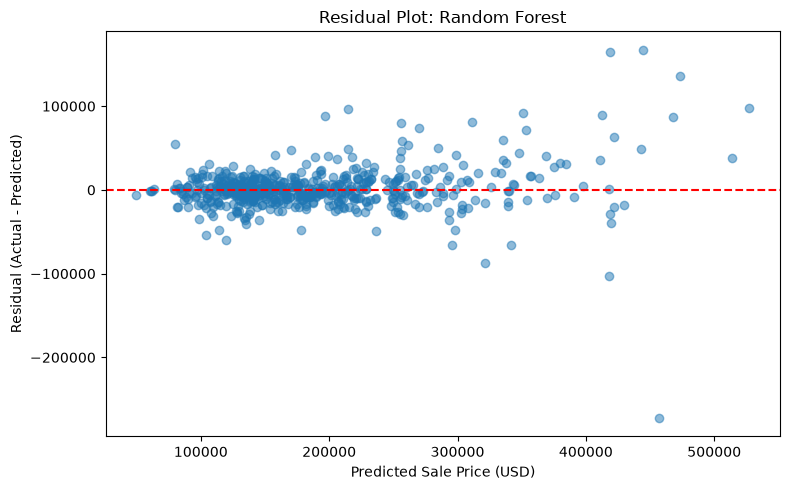

Mean residual: 1314.19


In [111]:
# Calculate residuals
residuals = y_test.to_numpy() - best_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title(f"Residual Plot: {best_model_name}")
plt.xlabel("Predicted Sale Price (USD)")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()

plt.savefig(
    figures / "06_residual_plot.png",
    dpi=150
)

plt.show()

print("Mean residual:", round(residuals.mean(), 2))

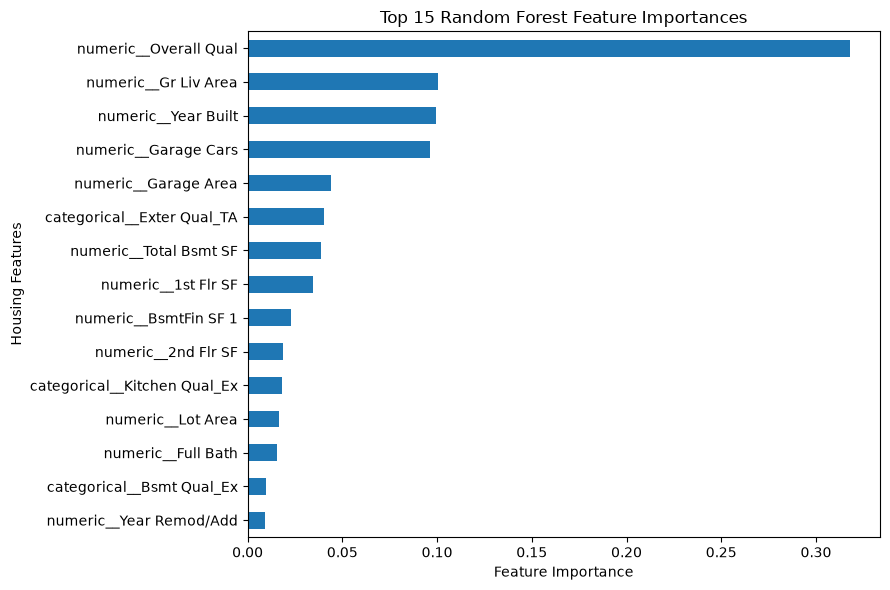

,Importance
numeric__Overall Qual,0.317894
numeric__Gr Liv Area,0.100475
numeric__Year Built,0.099211
numeric__Garage Cars,0.096428
numeric__Garage Area,0.044065
categorical__Exter Qual_TA,0.040301
numeric__Total Bsmt SF,0.038925
numeric__1st Flr SF,0.034276
numeric__BsmtFin SF 1,0.023129
numeric__2nd Flr SF,0.018502


In [112]:
# Random Forest feature importance
fitted_forest = forest_search.best_estimator_

feature_names = (
    fitted_forest.named_steps["preprocessing"]
    .get_feature_names_out()
)

importance = pd.Series(
    fitted_forest.named_steps["model"].feature_importances_,
    index=feature_names
)

top_features = importance.nlargest(15)

plt.figure(figsize=(9, 6))

top_features.sort_values().plot(kind="barh")

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Housing Features")

plt.tight_layout()

plt.savefig(
    figures / "07_feature_importance.png",
    dpi=150
)

plt.show()

display(top_features.to_frame("Importance"))

In [113]:
# Final regression summary
selected_result = results_df.loc[
    results_df["Model"] == best_model_name
].iloc[0]

baseline_result = results_df.loc[
    results_df["Model"] == "Median Baseline"
].iloc[0]

rmse_improvement = (
    (baseline_result["RMSE"] - selected_result["RMSE"])
    / baseline_result["RMSE"]
) * 100

print("AMES HOUSING REGRESSION RESULTS")

print("\nDataset:", "Ames Housing")
print("Total records:", len(df_clean))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nSelected model:", best_model_name)

print("\nModel evaluation:")
print("MAE:", round(selected_result["MAE"], 2))
print("RMSE:", round(selected_result["RMSE"], 2))
print("R²:", round(selected_result["R2"], 3))

print("\nRMSE improvement over baseline:")
print(f"{rmse_improvement:.2f}%")

print("\nCross-validation comparison:")
display(cv_results.round(2))

print("\nTest performance comparison:")
display(results_df.round(3))

print("\nTop five Random Forest features:")
display(importance.nlargest(5).to_frame("Importance"))

AMES HOUSING REGRESSION RESULTS

Dataset: Ames Housing
Total records: 2930
Training records: 2344
Testing records: 586

Selected model: Random Forest

Model evaluation:
MAE: 15232.77
RMSE: 26421.22
R²: 0.913

RMSE improvement over baseline:
71.99%

Cross-validation comparison:


,Model,CV RMSE
0,Random Forest,25678.41
1,Ridge Regression,29422.09
2,Median Baseline,79307.86



Test performance comparison:


,Model,MAE,RMSE,R2
0,Random Forest,15232.772,26421.224,0.913
1,Ridge Regression,16068.382,28742.481,0.897
2,Median Baseline,63838.101,94322.625,-0.110



Top five Random Forest features:


,Importance
numeric__Overall Qual,0.317894
numeric__Gr Liv Area,0.100475
numeric__Year Built,0.099211
numeric__Garage Cars,0.096428
numeric__Garage Area,0.044065
